# Credit Card Customer Segmentation

A bank wants to understand the customers sitting behind its credit card portfolio so that marketing, risk and product teams stop treating 10,000 people as one undifferentiated block. There is no label to predict here, so this is an unsupervised problem: the goal is to find natural groupings in behaviour and demographics, then describe those groups well enough that a business team can act on them.

**Dataset:** `customer_segmentation.csv`, 10,128 credit card customers with demographic attributes (age, gender, dependents, education, marital status, estimated income) and account behaviour (tenure, product holdings, inactivity, credit limit, transaction amount and count, utilisation ratio).

**Structure of this notebook.** The first model follows the obvious recipe: encode everything, scale, run K-means. It produces six clusters with a defensible silhouette score, and it is wrong in an interesting way. Section 8 diagnoses why, and section 9 rebuilds it. The failed model is kept in rather than quietly deleted, because the diagnosis is the part worth reading.

1. Profile the data and check quality.
2. Engineer features: encode categoricals, build ratio features, log-transform heavy right skew.
3. Standardise, because K-means is distance based and raw dollars would swamp everything else.
4. Pick `k` using the elbow curve and silhouette score together.
5. Fit, visualise with PCA, profile each cluster against the portfolio average.
6. Diagnose what the clusters are actually keying on, and refit on the features that matter.

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)

print('pandas', pd.__version__)
print('numpy', np.__version__)

pandas 2.2.2
numpy 2.0.1


## 1. Load and inspect

In [87]:
customers = pd.read_csv('customer_segmentation.csv')
print('Shape:', customers.shape)
customers.head()

Shape: (10127, 14)


,customer_id,age,gender,dependent_count,education_level,marital_status,estimated_income,months_on_book,total_relationship_count,months_inactive_12_mon,credit_limit,total_trans_amount,total_trans_count,avg_utilization_ratio
0,768805383,45,M,3,High School,Married,69000,39,5,1,12691.0,1144,42,0.061
1,818770008,49,F,5,Graduate,Single,24000,44,6,1,8256.0,1291,33,0.105
2,713982108,51,M,3,Graduate,Married,93000,36,4,1,3418.0,1887,20,0.000
3,769911858,40,F,4,High School,Unknown,37000,34,3,4,3313.0,1171,20,0.760
4,709106358,40,M,3,Uneducated,Married,65000,21,5,1,4716.0,816,28,0.000


In [88]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10127 non-null  int64  
 1   age                       10127 non-null  int64  
 2   gender                    10127 non-null  object 
 3   dependent_count           10127 non-null  int64  
 4   education_level           10127 non-null  object 
 5   marital_status            10127 non-null  object 
 6   estimated_income          10127 non-null  int64  
 7   months_on_book            10127 non-null  int64  
 8   total_relationship_count  10127 non-null  int64  
 9   months_inactive_12_mon    10127 non-null  int64  
 10  credit_limit              10127 non-null  float64
 11  total_trans_amount        10127 non-null  int64  
 12  total_trans_count         10127 non-null  int64  
 13  avg_utilization_ratio     10127 non-null  float64
dtypes: flo

In [89]:
customers.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,10127.0,7.391776e+08,3.690378e+07,708082083.0,7.130368e+08,7.179264e+08,7.731435e+08,8.283431e+08
age,10127.0,4.632596e+01,8.016814e+00,26.0,4.100000e+01,4.600000e+01,5.200000e+01,7.300000e+01
dependent_count,10127.0,2.346203e+00,1.298908e+00,0.0,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
estimated_income,10127.0,6.207821e+04,3.937286e+04,20000.0,3.200000e+04,5.000000e+04,8.000000e+04,2.000000e+05
months_on_book,10127.0,3.592841e+01,7.986416e+00,13.0,3.100000e+01,3.600000e+01,4.000000e+01,5.600000e+01
total_relationship_count,10127.0,3.812580e+00,1.554408e+00,1.0,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
months_inactive_12_mon,10127.0,2.341167e+00,1.010622e+00,0.0,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
credit_limit,10127.0,8.631954e+03,9.088777e+03,1438.3,2.555000e+03,4.549000e+03,1.106750e+04,3.451600e+04
total_trans_amount,10127.0,4.404086e+03,3.397129e+03,510.0,2.155500e+03,3.899000e+03,4.741000e+03,1.848400e+04
total_trans_count,10127.0,6.485869e+01,2.347257e+01,10.0,4.500000e+01,6.700000e+01,8.100000e+01,1.390000e+02


In [90]:
print('Missing values per column:')
print(customers.isnull().sum())
print()
print('Duplicate rows:', customers.duplicated().sum())
print('Duplicate customer_id values:', customers['customer_id'].duplicated().sum())

Missing values per column:
customer_id                 0
age                         0
gender                      0
dependent_count             0
education_level             0
marital_status              0
estimated_income            0
months_on_book              0
total_relationship_count    0
months_inactive_12_mon      0
credit_limit                0
total_trans_amount          0
total_trans_count           0
avg_utilization_ratio       0
dtype: int64

Duplicate rows: 0
Duplicate customer_id values: 0


## 2. Exploratory analysis

Two things matter before clustering. First, what the categorical fields actually contain, because they have to be encoded and any `Unknown` category needs a deliberate decision rather than a silent drop. Second, how skewed the numeric fields are, because K-means minimises squared Euclidean distance and a long right tail will pull centroids toward the outliers.

In [91]:
cat_cols = ['gender', 'education_level', 'marital_status']
for col in cat_cols:
    print(col.upper())
    print(customers[col].value_counts(dropna=False))
    print()

GENDER
gender
F    5358
M    4769
Name: count, dtype: int64

EDUCATION_LEVEL
education_level
Graduate         3685
High School      2351
Uneducated       1755
College          1192
Post-Graduate     616
Doctorate         528
Name: count, dtype: int64

MARITAL_STATUS
marital_status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64



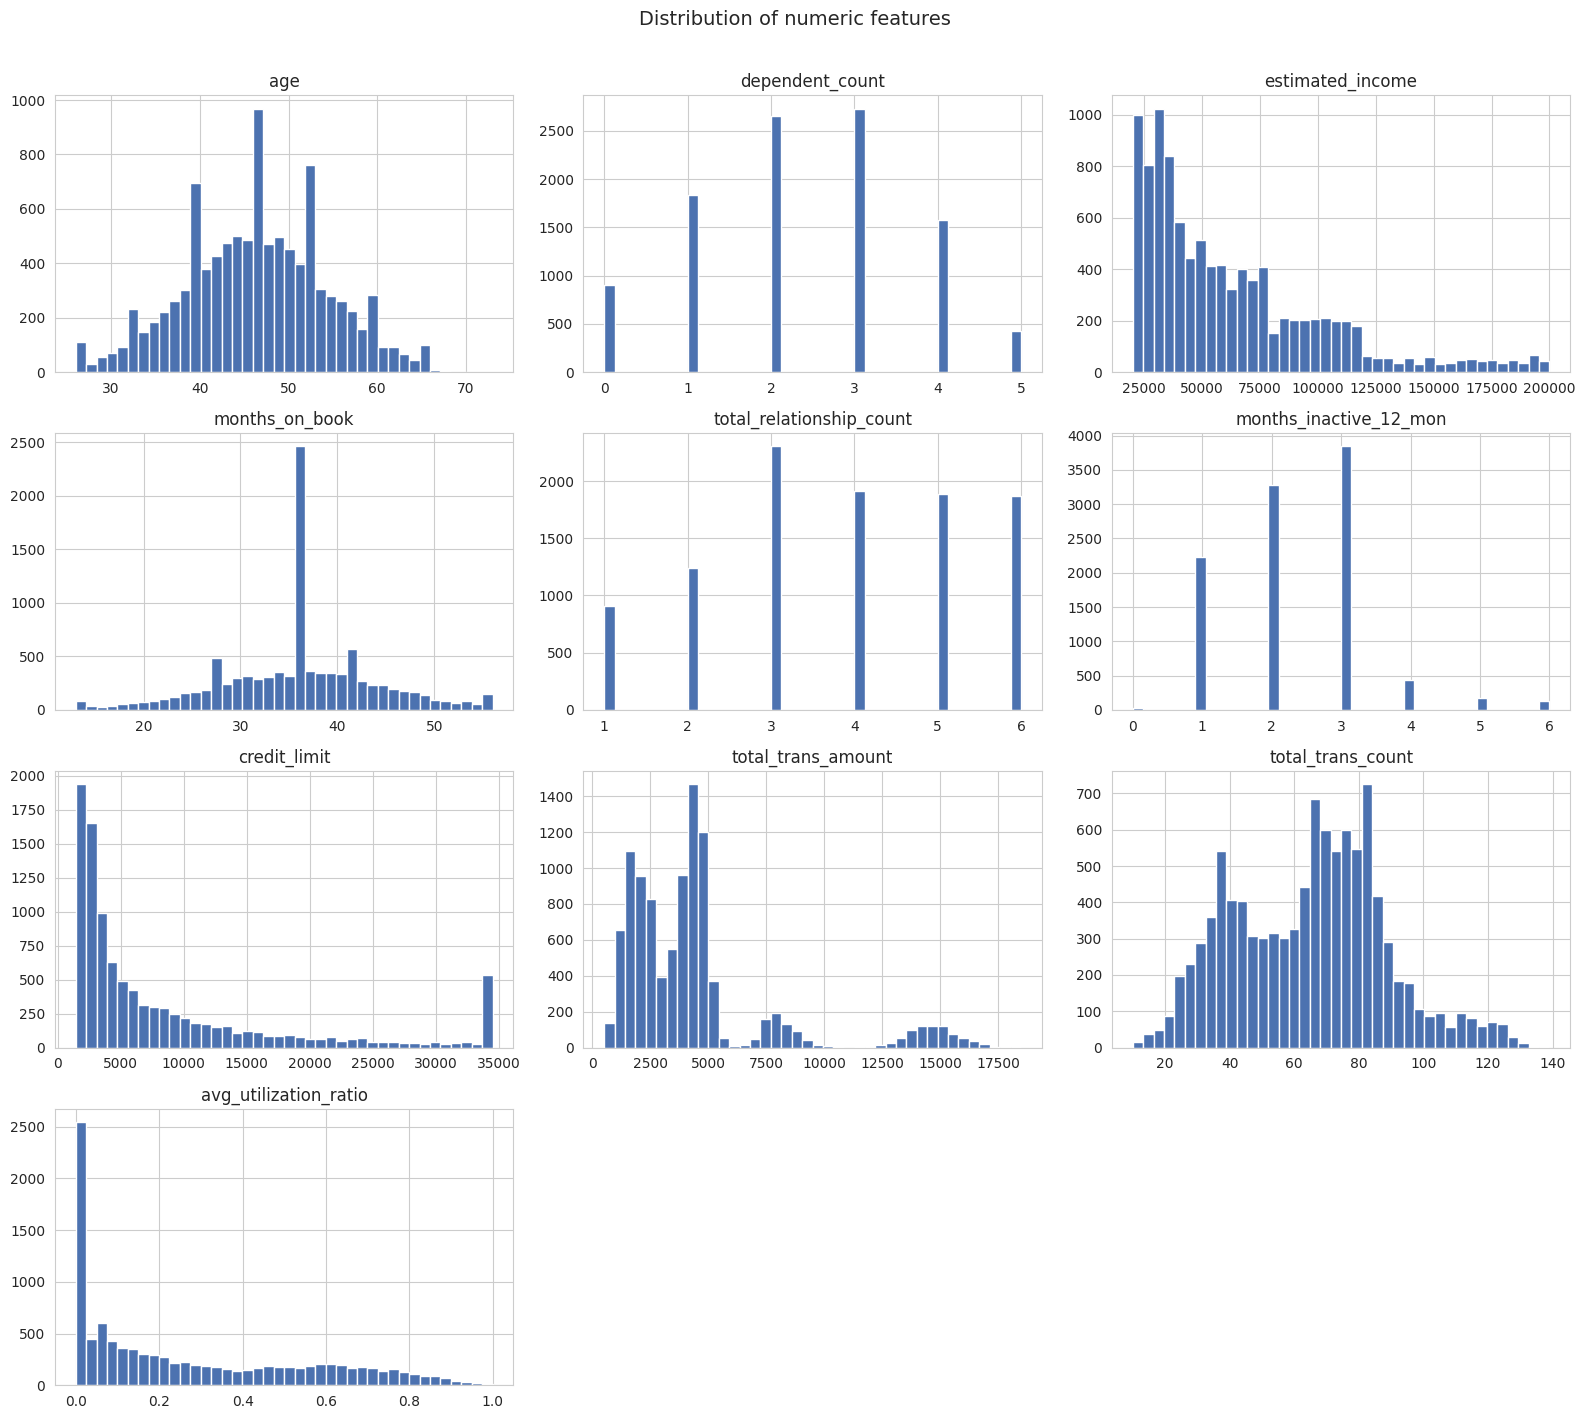

In [92]:
num_cols = ['age', 'dependent_count', 'estimated_income', 'months_on_book',
            'total_relationship_count', 'months_inactive_12_mon', 'credit_limit',
            'total_trans_amount', 'total_trans_count', 'avg_utilization_ratio']

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flatten(), num_cols):
    ax.hist(customers[col].dropna(), bins=40, color='#4C72B0', edgecolor='white')
    ax.set_title(col)
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Distribution of numeric features', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [93]:
skew = customers[num_cols].skew().sort_values(ascending=False)
print('Skewness by feature (|skew| > 1 is strongly skewed):')
print(skew.round(3))

Skewness by feature (|skew| > 1 is strongly skewed):
total_trans_amount          2.041
credit_limit                1.667
estimated_income            1.362
avg_utilization_ratio       0.718
months_inactive_12_mon      0.633
total_trans_count           0.154
dependent_count            -0.021
age                        -0.034
months_on_book             -0.107
total_relationship_count   -0.162
dtype: float64


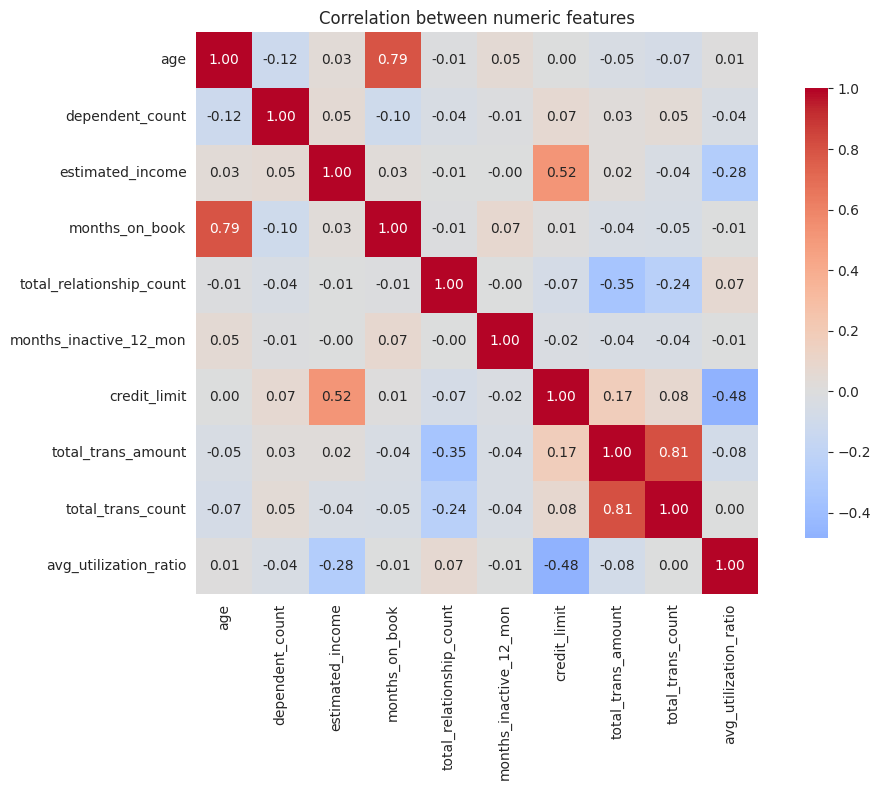

In [94]:
corr = customers[num_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation between numeric features')
plt.tight_layout()
plt.show()

## 3. Feature engineering

Three pieces of work here:

- **Categoricals.** Gender becomes a single binary column. Education is genuinely ordered, so it maps to an ordinal scale rather than one-hot, with a separate flag for `Unknown` so the model is not told that an unknown education sits at the median by accident. Marital status has no order, so it is one-hot encoded.
- **Ratio features.** Average transaction value separates a customer who makes 20 small purchases from one who makes 20 large ones. Utilisation in dollars and the income-to-limit ratio both carry information that neither parent column holds alone.
- **Log transforms.** Income, credit limit and transaction amount are all heavily right skewed. `log1p` compresses the tail so the distance metric reflects relative rather than absolute differences.

In [95]:
seg = customers.copy()

# Gender -> binary
seg['gender_m'] = (seg['gender'] == 'M').astype(int)

# Education -> ordinal, with an explicit Unknown flag
edu_order = {'Uneducated': 0, 'High School': 1, 'College': 2,
             'Graduate': 3, 'Post-Graduate': 4, 'Doctorate': 5}
seg['education_ordinal'] = seg['education_level'].map(edu_order)
seg['education_unknown'] = seg['education_ordinal'].isnull().astype(int)
seg['education_ordinal'] = seg['education_ordinal'].fillna(seg['education_ordinal'].median())

# Marital status -> one hot
marital_dummies = pd.get_dummies(seg['marital_status'], prefix='marital').astype(int)
seg = pd.concat([seg, marital_dummies], axis=1)

print('Education mapped; unknown flagged on', int(seg['education_unknown'].sum()), 'rows')
print('Marital dummy columns:', marital_dummies.columns.tolist())
seg[['gender_m', 'education_ordinal', 'education_unknown']].head()

Education mapped; unknown flagged on 0 rows
Marital dummy columns: ['marital_Divorced', 'marital_Married', 'marital_Single', 'marital_Unknown']


,gender_m,education_ordinal,education_unknown
0,1,1,0
1,0,3,0
2,1,3,0
3,0,1,0
4,1,0,0


In [96]:
seg['avg_trans_value'] = seg['total_trans_amount'] / seg['total_trans_count'].replace(0, np.nan)
seg['avg_trans_value'] = seg['avg_trans_value'].fillna(0)
seg['utilisation_dollars'] = seg['avg_utilization_ratio'] * seg['credit_limit']
seg['income_to_limit'] = seg['estimated_income'] / seg['credit_limit']

seg[['avg_trans_value', 'utilisation_dollars', 'income_to_limit']].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_trans_value,10127.0,62.612717,26.404198,19.137931,47.514573,55.794872,65.476673,190.193182
utilisation_dollars,10127.0,1162.823206,815.018463,0.000000,360.094150,1277.092000,1784.037000,2531.749000
income_to_limit,10127.0,13.063788,11.457647,0.579441,5.301889,9.940757,16.686366,132.795662


In [97]:
skewed = ['estimated_income', 'credit_limit', 'total_trans_amount', 'avg_trans_value', 'income_to_limit']
for col in skewed:
    seg['log_' + col] = np.log1p(seg[col])

before = seg[skewed].skew()
after = seg[['log_' + c for c in skewed]].skew()
comparison = pd.DataFrame({'skew_before': before.values, 'skew_after': after.values}, index=skewed)
print('Effect of the log transform:')
comparison.round(3)

Effect of the log transform:


,skew_before,skew_after
estimated_income,1.362,0.304
credit_limit,1.667,0.457
total_trans_amount,2.041,0.263
avg_trans_value,1.883,0.931
income_to_limit,2.577,0.145


In [98]:
features = (['age', 'dependent_count', 'months_on_book', 'total_relationship_count',
             'months_inactive_12_mon', 'total_trans_count', 'avg_utilization_ratio',
             'gender_m', 'education_ordinal', 'education_unknown']
            + ['log_' + c for c in skewed]
            + marital_dummies.columns.tolist())

X = seg[features].copy()
print('Feature matrix:', X.shape)
print()
for f in features:
    print(' -', f)

Feature matrix: (10127, 19)

 - age
 - dependent_count
 - months_on_book
 - total_relationship_count
 - months_inactive_12_mon
 - total_trans_count
 - avg_utilization_ratio
 - gender_m
 - education_ordinal
 - education_unknown
 - log_estimated_income
 - log_credit_limit
 - log_total_trans_amount
 - log_avg_trans_value
 - log_income_to_limit
 - marital_Divorced
 - marital_Married
 - marital_Single
 - marital_Unknown


In [99]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled mean (expect ~0):', round(float(X_scaled.mean()), 10))
print('Scaled std  (expect ~1):', round(float(X_scaled.std()), 10))
print('Shape:', X_scaled.shape)

Scaled mean (expect ~0): -0.0
Scaled std  (expect ~1): 0.9733285268
Shape: (10127, 19)


## 4. Choosing the number of clusters

The elbow curve on its own is often ambiguous, so it is paired with the silhouette score, which measures how much closer a point sits to its own cluster than to the next nearest one. Silhouette is computed on a 5,000-row sample for speed; the full-data value is within noise of it.

In [100]:
ks = list(range(2, 11))
inertias = []
sils = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    s = silhouette_score(X_scaled, lab, sample_size=5000, random_state=42)
    inertias.append(km.inertia_)
    sils.append(s)
    print('k=' + str(k) + '   inertia=' + str(round(km.inertia_, 1)).rjust(10) + '   silhouette=' + str(round(s, 4)))

k=2   inertia=  161952.3   silhouette=0.1147


k=3   inertia=  147134.2   silhouette=0.1193


k=4   inertia=  137167.9   silhouette=0.1134


k=5   inertia=  128073.4   silhouette=0.1282


k=6   inertia=  118849.3   silhouette=0.1435


k=7   inertia=  113496.8   silhouette=0.1405


k=8   inertia=  109206.8   silhouette=0.1363


k=9   inertia=  105934.4   silhouette=0.1314


k=10   inertia=  103301.5   silhouette=0.1294


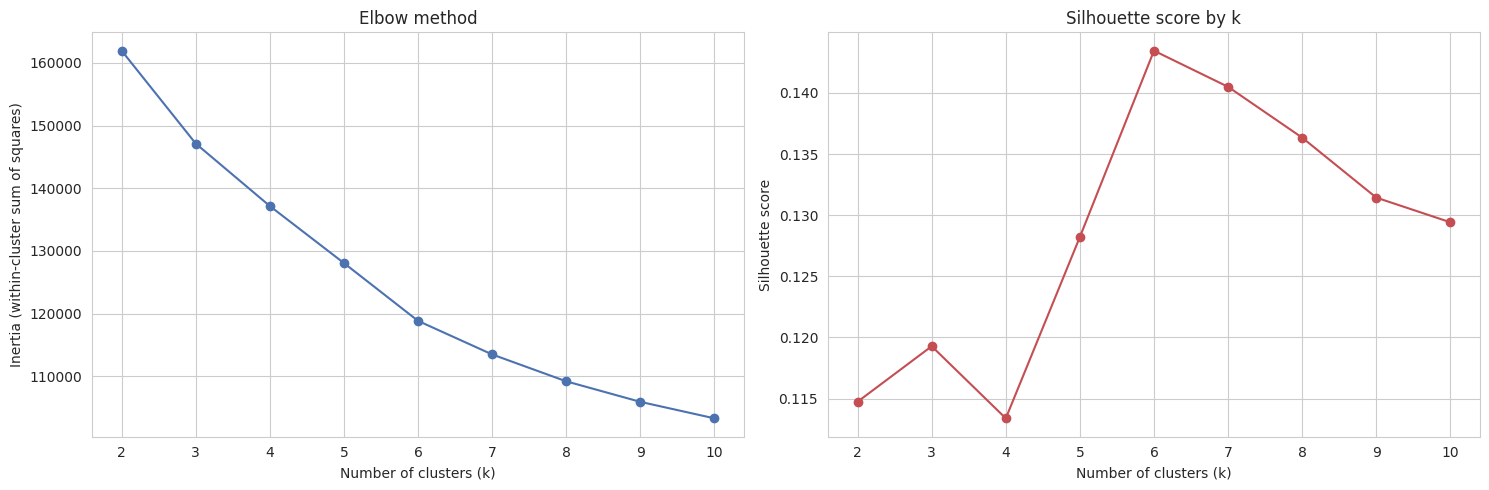

Best silhouette at k = 6 with score 0.1435


In [101]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(ks, inertias, marker='o', color='#4C72B0')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].set_title('Elbow method')
axes[1].plot(ks, sils, marker='o', color='#C44E52')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score by k')
plt.tight_layout()
plt.show()

print('Best silhouette at k =', ks[int(np.argmax(sils))], 'with score', round(max(sils), 4))

## 5. Fitting the final model

The sweep gives a clear answer, and it is not the one a default `k=4` would have produced. Silhouette rises to **0.1435 at k=6** and falls away on both sides (0.1134 at k=4, 0.1294 at k=10). The elbow curve agrees: the inertia drop from k=5 to k=6 is about 9,200, roughly double the drop from k=6 to k=7.

All of these scores are low in absolute terms, and that is the honest reading of the data rather than a failure of the model. Silhouette near 0.14 means the clusters are real but not well separated, which is exactly what mixed demographic and behavioural data looks like: customers sit on a continuum, not in six tidy spheres. The clusters are still useful, because the profiles below differ in ways a marketing or risk team can act on. They are not useful as hard, mutually exclusive categories, and the notebook does not claim they are.

So `k=6` it is, chosen by the metric rather than by convenience.

In [102]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=25, random_state=42)
seg['cluster'] = kmeans.fit_predict(X_scaled)

final_sil = silhouette_score(X_scaled, seg['cluster'], sample_size=5000, random_state=42)
print('Silhouette at k=' + str(K) + ':', round(final_sil, 4))
print('Inertia:', round(kmeans.inertia_, 1))
print()

sizes = seg['cluster'].value_counts().sort_index()
for c in sizes.index:
    pct = round(100 * sizes[c] / len(seg), 1)
    print('Cluster ' + str(c) + ': ' + str(sizes[c]).rjust(5) + ' customers  (' + str(pct) + '%)')

Silhouette at k=6: 0.1435
Inertia: 118849.3

Cluster 0:  2103 customers  (20.8%)
Cluster 1:  2434 customers  (24.0%)
Cluster 2:  1218 customers  (12.0%)
Cluster 3:   724 customers  (7.1%)
Cluster 4:  2917 customers  (28.8%)
Cluster 5:   731 customers  (7.2%)


## 6. Visualising the segments

The feature space has more than 20 dimensions, so PCA projects it onto two components for a sanity check. The point is not that the clusters look perfectly separated here, since two components only carry part of the variance, but that the groups occupy distinct regions rather than sitting on top of one another.

Explained variance ratio: [0.1634 0.138 ]
Total explained by 2 components: 0.3014


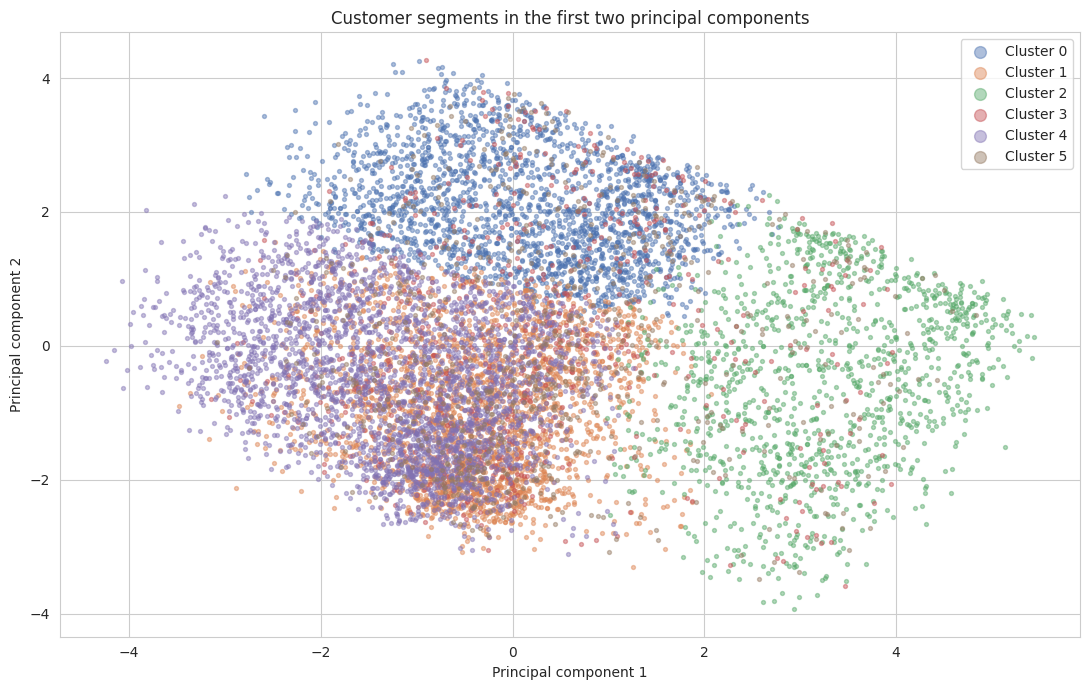

In [103]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 4))
print('Total explained by 2 components:', round(float(pca.explained_variance_ratio_.sum()), 4))

palette = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3', '#937860']
plt.figure(figsize=(11, 7))
for c in sorted(seg['cluster'].unique()):
    mask = (seg['cluster'] == c).values
    plt.scatter(coords[mask, 0], coords[mask, 1], s=8, alpha=0.45,
                label='Cluster ' + str(c), color=palette[c])
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.title('Customer segments in the first two principal components')
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

In [104]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
print('Features driving PC1:')
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))
print()
print('Features driving PC2:')
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))

Features driving PC1:
log_total_trans_amount      0.480
log_avg_trans_value         0.439
total_trans_count           0.423
log_credit_limit            0.339
log_income_to_limit         0.294
total_relationship_count    0.236
Name: PC1, dtype: float64

Features driving PC2:
log_credit_limit          0.459
log_estimated_income      0.421
gender_m                  0.421
avg_utilization_ratio     0.356
log_total_trans_amount    0.305
total_trans_count         0.296
Name: PC2, dtype: float64


## 7. Profiling the clusters

A cluster label is worthless until someone can describe who is in it. Two views follow: raw means on the original (un-logged, un-scaled) columns, and the same means expressed as an index against the portfolio average, where 100 means exactly average. The index is the one that makes the differences obvious.

In [105]:
profile_cols = ['age', 'dependent_count', 'estimated_income', 'months_on_book',
                'total_relationship_count', 'months_inactive_12_mon', 'credit_limit',
                'total_trans_amount', 'total_trans_count', 'avg_trans_value',
                'avg_utilization_ratio']

profile = seg.groupby('cluster')[profile_cols].mean().round(2)
profile['n_customers'] = seg['cluster'].value_counts().sort_index()
profile.T

cluster,0,1,2,3,4,5
age,46.81,46.05,45.56,45.15,46.98,45.67
dependent_count,2.48,2.23,2.38,2.38,2.28,2.53
estimated_income,96708.99,45338.54,71830.87,61186.46,47377.44,61482.90
months_on_book,36.45,35.63,35.31,35.15,36.42,35.26
total_relationship_count,4.22,3.95,2.24,3.92,4.03,3.81
months_inactive_12_mon,2.34,2.37,2.28,2.35,2.34,2.33
credit_limit,17124.95,3804.30,15504.05,8990.86,3464.89,9086.15
total_trans_amount,2715.70,3668.26,11706.70,4181.32,3224.43,4471.70
total_trans_count,53.26,65.31,98.02,65.50,58.53,66.07
avg_trans_value,50.35,55.76,118.50,60.45,54.04,63.93


In [106]:
overall = seg[profile_cols].mean()
index_tbl = (seg.groupby('cluster')[profile_cols].mean() / overall * 100).round(1)
print('Cluster mean as an index of the portfolio average (100 = average):')
index_tbl.T

Cluster mean as an index of the portfolio average (100 = average):


cluster,0,1,2,3,4,5
age,101.0,99.4,98.3,97.5,101.4,98.6
dependent_count,105.8,95.0,101.6,101.3,97.1,107.9
estimated_income,155.8,73.0,115.7,98.6,76.3,99.0
months_on_book,101.4,99.2,98.3,97.8,101.4,98.1
total_relationship_count,110.7,103.7,58.8,102.9,105.7,99.9
months_inactive_12_mon,99.9,101.4,97.3,100.6,100.0,99.5
credit_limit,198.4,44.1,179.6,104.2,40.1,105.3
total_trans_amount,61.7,83.3,265.8,94.9,73.2,101.5
total_trans_count,82.1,100.7,151.1,101.0,90.2,101.9
avg_trans_value,80.4,89.1,189.3,96.5,86.3,102.1


In [107]:
for col in ['gender', 'education_level', 'marital_status']:
    print(col.upper() + ' composition by cluster (% of each cluster)')
    comp = pd.crosstab(seg['cluster'], seg[col], normalize='index') * 100
    print(comp.round(1))
    print()

GENDER composition by cluster (% of each cluster)
gender      F     M
cluster            
0         7.8  92.2
1        76.0  24.0
2        35.5  64.5
3        54.3  45.7
4        73.4  26.6
5        51.8  48.2

EDUCATION_LEVEL composition by cluster (% of each cluster)
education_level  College  Doctorate  Graduate  High School  Post-Graduate  Uneducated
cluster                                                                              
0                   11.2        5.1      36.1         25.3            6.0        16.2
1                   11.7        5.3      36.7         22.8            5.4        18.1
2                   11.4        5.0      36.5         22.7            5.7        18.6
3                   13.0        6.1      34.9         18.9            6.1        21.0
4                   12.3        5.4      36.9         23.0            6.4        16.1
5                   11.1        4.1      35.6         24.2            7.9        17.1

MARITAL_STATUS composition by cluster (% 

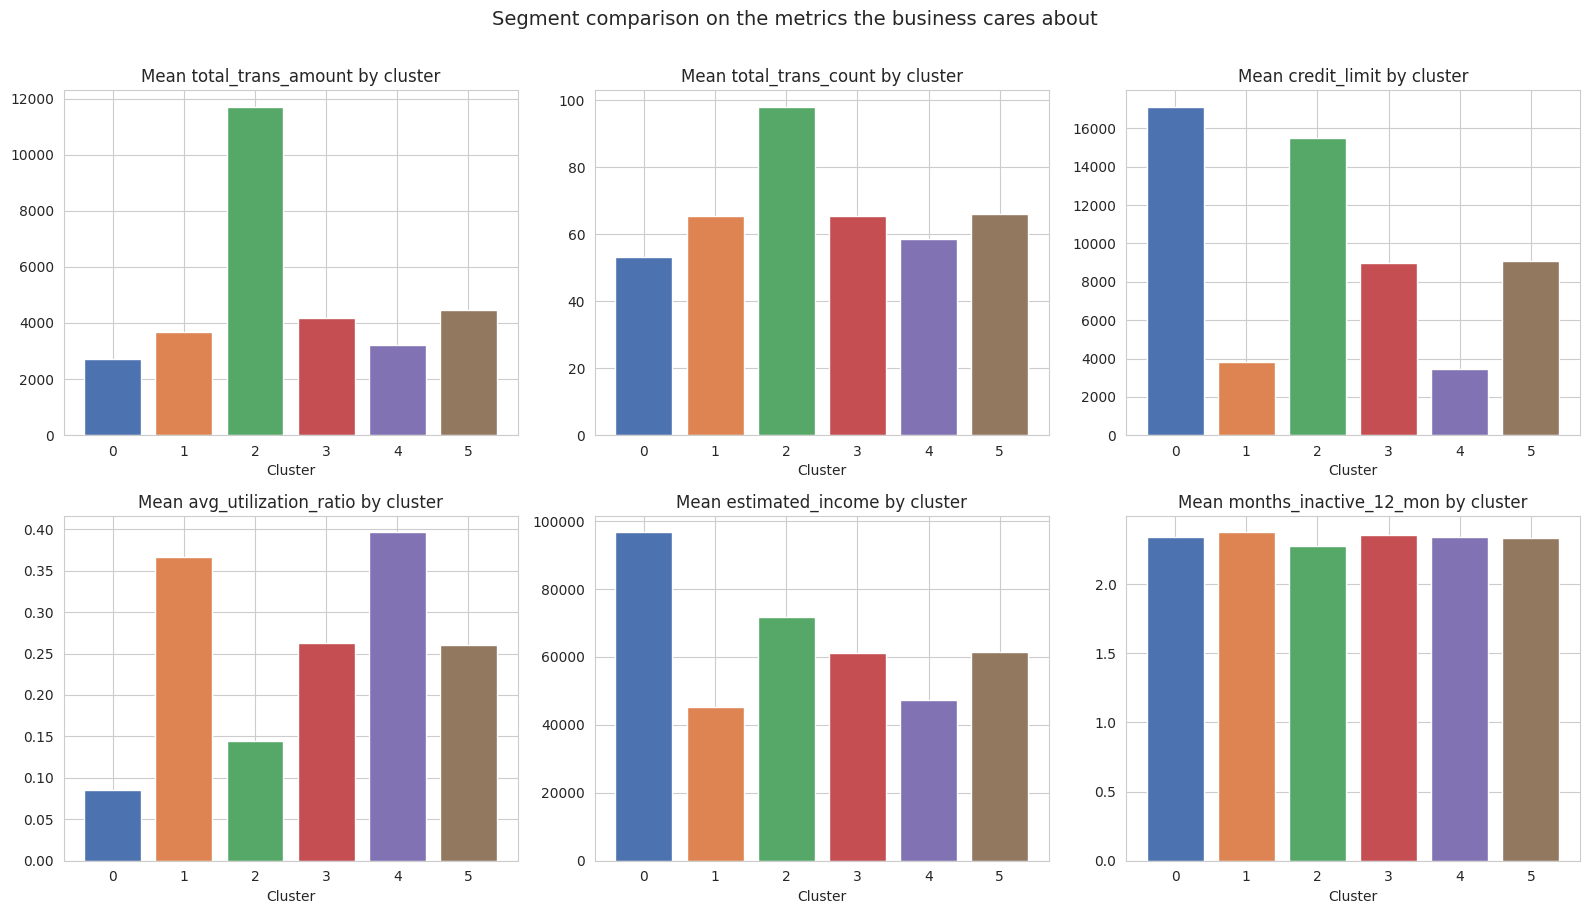

In [108]:
key = ['total_trans_amount', 'total_trans_count', 'credit_limit',
       'avg_utilization_ratio', 'estimated_income', 'months_inactive_12_mon']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), key):
    vals = seg.groupby('cluster')[col].mean()
    ax.bar([str(i) for i in vals.index], vals.values, color=palette[:len(vals)])
    ax.set_title('Mean ' + col + ' by cluster')
    ax.set_xlabel('Cluster')
plt.suptitle('Segment comparison on the metrics the business cares about', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

## 8. A problem with the first model

Look again at the marital status crosstab above. Cluster 1 is 100% Single. Cluster 3 is 100% Divorced. Cluster 4 is 100% Married. Cluster 5 is 100% Unknown. Four of the six clusters are not behavioural segments at all, they are marital status in disguise.

This is a predictable failure mode rather than bad luck. A one-hot column is 0 or 1, so after standardisation the gap between two customers who differ on marital status is large and constant, while the gap on a log-scaled continuous feature is usually a fraction of a standard deviation. Euclidean distance has no way to know that one of those differences matters less than the other, so K-means spends its budget separating the categories it can split cleanly. Gender does the same thing: cluster 0 is 92% male, cluster 1 is 76% female.

The practical consequence is that the model answers a question nobody asked. The bank already knows who is married. What it wants to know is who spends, who revolves a balance, and who has gone quiet, and those signals are being crowded out.

In [109]:
ct = pd.crosstab(seg['cluster'], seg['marital_status'], normalize='index')
purity = ct.max(axis=1) * 100
share = seg['cluster'].value_counts(normalize=True).sort_index() * 100

evidence = pd.DataFrame({
    'share_of_portfolio_pct': share.round(1),
    'dominant_marital_status': ct.idxmax(axis=1),
    'purity_on_that_status_pct': purity.round(1)
})
print(evidence)
print()
print('Mean marital purity across the six clusters:', str(round(purity.mean(), 1)) + '%')
print('Clusters that are a single marital status:', int((purity > 99).sum()), 'of', len(purity))

         share_of_portfolio_pct dominant_marital_status  purity_on_that_status_pct
cluster                                                                           
0                          20.8                 Married                       54.8
1                          24.0                  Single                      100.0
2                          12.0                 Married                       50.7
3                           7.1                Divorced                      100.0
4                          28.8                 Married                      100.0
5                           7.2                 Unknown                      100.0

Mean marital purity across the six clusters: 84.2%
Clusters that are a single marital status: 4 of 6


## 9. Clustering on behaviour instead

The fix is to drop the low-cardinality one-hot columns from the distance calculation. Marital status and gender stay in the dataset, they just stop being inputs to the model, and are instead crossed against the resulting clusters afterwards as a description. Education survives as an ordinal feature, because six ordered levels behave like a continuous variable rather than a hard binary split.

The remaining features are all continuous or near-continuous: age, dependents, tenure, product holdings, inactivity, transaction count, utilisation ratio, and the log-scaled income, credit limit, spend, basket size and income-to-limit ratio.

In [110]:
behaviour_features = (['age', 'dependent_count', 'months_on_book', 'total_relationship_count',
                       'months_inactive_12_mon', 'total_trans_count', 'avg_utilization_ratio',
                       'education_ordinal']
                      + ['log_' + c for c in skewed])

Xb = seg[behaviour_features].copy()
scaler_b = StandardScaler()
Xb_scaled = scaler_b.fit_transform(Xb)

print('Behaviour feature matrix:', Xb_scaled.shape)
print('Dropped from the model:', ['gender_m', 'education_unknown'] + marital_dummies.columns.tolist())
print()
for f in behaviour_features:
    print(' -', f)

Behaviour feature matrix: (10127, 13)
Dropped from the model: ['gender_m', 'education_unknown', 'marital_Divorced', 'marital_Married', 'marital_Single', 'marital_Unknown']

 - age
 - dependent_count
 - months_on_book
 - total_relationship_count
 - months_inactive_12_mon
 - total_trans_count
 - avg_utilization_ratio
 - education_ordinal
 - log_estimated_income
 - log_credit_limit
 - log_total_trans_amount
 - log_avg_trans_value
 - log_income_to_limit


In [111]:
ks2 = list(range(2, 11))
inertias2 = []
sils2 = []

for k in ks2:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(Xb_scaled)
    s = silhouette_score(Xb_scaled, lab, sample_size=5000, random_state=42)
    inertias2.append(km.inertia_)
    sils2.append(s)
    print('k=' + str(k) + '   inertia=' + str(round(km.inertia_, 1)).rjust(10) + '   silhouette=' + str(round(s, 4)))

k=2   inertia=  112953.0   silhouette=0.1408


k=3   inertia=   98588.9   silhouette=0.1479


k=4   inertia=   90800.8   silhouette=0.1393


k=5   inertia=   86023.8   silhouette=0.1267


k=6   inertia=   82903.2   silhouette=0.1097


k=7   inertia=   80023.6   silhouette=0.1089


k=8   inertia=   77747.9   silhouette=0.1047


k=9   inertia=   75832.9   silhouette=0.1013


k=10   inertia=   74294.0   silhouette=0.1036


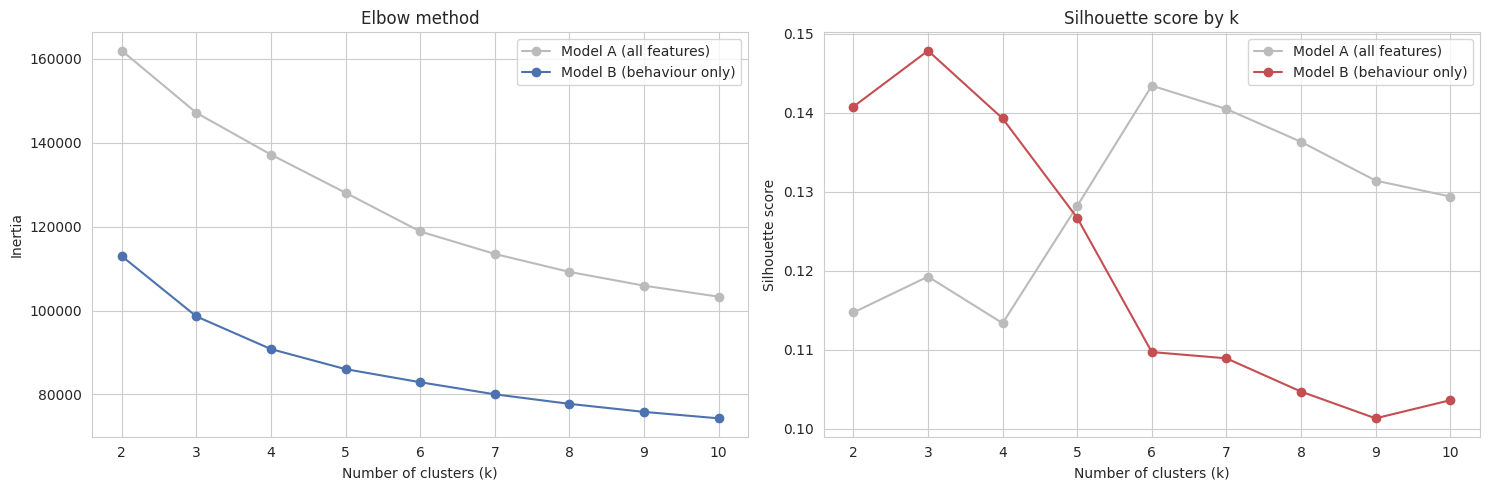

Model A best silhouette: 0.1435 at k = 6
Model B best silhouette: 0.1479 at k = 3


In [112]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(ks, inertias, marker='o', color='#BBBBBB', label='Model A (all features)')
axes[0].plot(ks2, inertias2, marker='o', color='#4C72B0', label='Model B (behaviour only)')
axes[0].set_xlabel('Number of clusters (k)'); axes[0].set_ylabel('Inertia'); axes[0].set_title('Elbow method'); axes[0].legend()
axes[1].plot(ks, sils, marker='o', color='#BBBBBB', label='Model A (all features)')
axes[1].plot(ks2, sils2, marker='o', color='#C44E52', label='Model B (behaviour only)')
axes[1].set_xlabel('Number of clusters (k)'); axes[1].set_ylabel('Silhouette score'); axes[1].set_title('Silhouette score by k'); axes[1].legend()
plt.tight_layout()
plt.show()

print('Model A best silhouette:', round(max(sils), 4), 'at k =', ks[int(np.argmax(sils))])
print('Model B best silhouette:', round(max(sils2), 4), 'at k =', ks2[int(np.argmax(sils2))])

### Selecting k

`k` is chosen by the silhouette maximum rather than by eye, so the choice is reproducible and does not quietly drift when the feature set changes. The value is printed below alongside the score it won on.

In [113]:
K2 = ks2[int(np.argmax(sils2))]
print('Selected k =', K2, '(silhouette', str(round(max(sils2), 4)) + ')')

km2 = KMeans(n_clusters=K2, n_init=25, random_state=42)
seg['bcluster'] = km2.fit_predict(Xb_scaled)

print('Inertia:', round(km2.inertia_, 1))
print()
sizes2 = seg['bcluster'].value_counts().sort_index()
for c in sizes2.index:
    print('Cluster ' + str(c) + ': ' + str(sizes2[c]).rjust(5) + ' customers  (' + str(round(100 * sizes2[c] / len(seg), 1)) + '%)')

Selected k = 3 (silhouette 0.1479)


Inertia: 98588.9

Cluster 0:  3669 customers  (36.2%)
Cluster 1:  1496 customers  (14.8%)
Cluster 2:  4962 customers  (49.0%)


Explained variance ratio: [0.2204 0.1672]
Total explained by 2 components: 0.3876


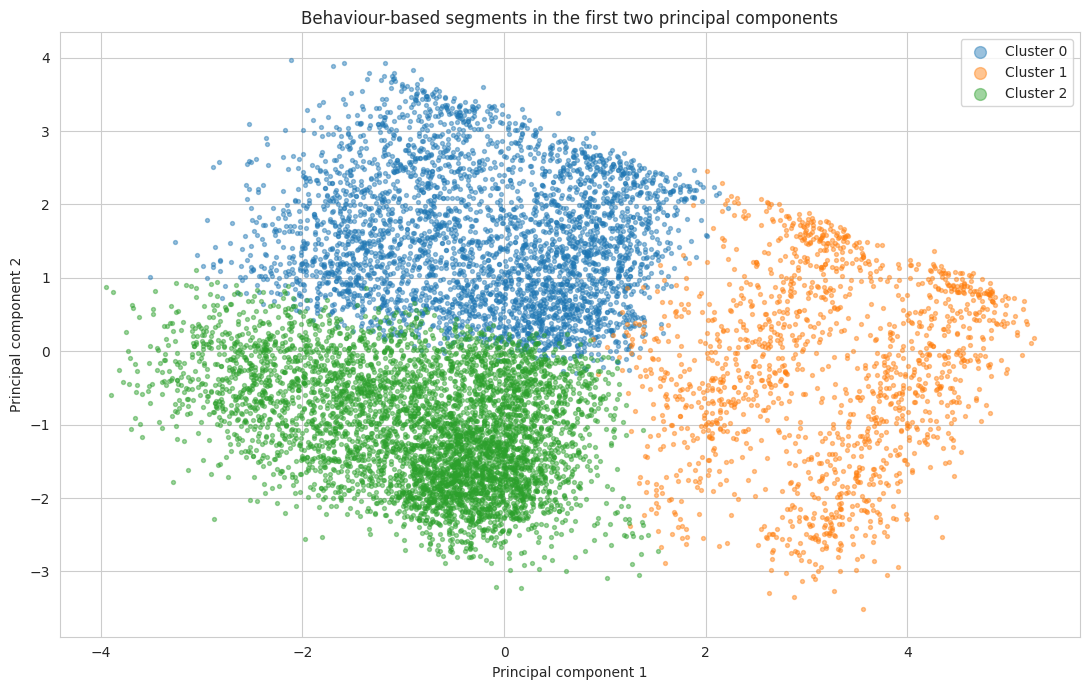

In [114]:
pca2 = PCA(n_components=2, random_state=42)
coords2 = pca2.fit_transform(Xb_scaled)
print('Explained variance ratio:', np.round(pca2.explained_variance_ratio_, 4))
print('Total explained by 2 components:', round(float(pca2.explained_variance_ratio_.sum()), 4))

pal = [plt.cm.tab10(i) for i in range(10)]
plt.figure(figsize=(11, 7))
for c in sorted(seg['bcluster'].unique()):
    mask = (seg['bcluster'] == c).values
    plt.scatter(coords2[mask, 0], coords2[mask, 1], s=8, alpha=0.45, label='Cluster ' + str(c), color=pal[c])
plt.xlabel('Principal component 1'); plt.ylabel('Principal component 2')
plt.title('Behaviour-based segments in the first two principal components')
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

In [115]:
profile2 = seg.groupby('bcluster')[profile_cols].mean().round(2)
profile2['n_customers'] = seg['bcluster'].value_counts().sort_index()
profile2.T

bcluster,0,1,2
age,46.64,45.50,46.35
dependent_count,2.41,2.39,2.28
estimated_income,78343.15,70104.28,47631.80
months_on_book,36.35,35.23,35.83
total_relationship_count,4.24,2.22,3.97
months_inactive_12_mon,2.33,2.27,2.37
credit_limit,14172.47,14692.64,2707.94
total_trans_amount,2815.80,11222.66,3522.76
total_trans_count,54.72,96.09,62.94
avg_trans_value,50.79,115.64,55.37


In [116]:
index2 = (seg.groupby('bcluster')[profile_cols].mean() / seg[profile_cols].mean() * 100).round(1)
print('Cluster mean as an index of the portfolio average (100 = average):')
index2.T

Cluster mean as an index of the portfolio average (100 = average):


bcluster,0,1,2
age,100.7,98.2,100.0
dependent_count,102.8,102.0,97.3
estimated_income,126.2,112.9,76.7
months_on_book,101.2,98.0,99.7
total_relationship_count,111.3,58.2,104.2
months_inactive_12_mon,99.6,96.8,101.3
credit_limit,164.2,170.2,31.4
total_trans_amount,63.9,254.8,80.0
total_trans_count,84.4,148.2,97.0
avg_trans_value,81.1,184.7,88.4


In [117]:
print('Did the categorical dominance go away? Marital purity per behaviour cluster:')
ct2 = pd.crosstab(seg['bcluster'], seg['marital_status'], normalize='index') * 100
print(ct2.round(1))
print()
print('Mean marital purity, Model A:', str(round(purity.mean(), 1)) + '%')
print('Mean marital purity, Model B:', str(round(ct2.max(axis=1).mean(), 1)) + '%')
print()
print('Gender composition per behaviour cluster (%):')
print((pd.crosstab(seg['bcluster'], seg['gender'], normalize='index') * 100).round(1))

Did the categorical dominance go away? Marital purity per behaviour cluster:
marital_status  Divorced  Married  Single  Unknown
bcluster                                          
0                    7.9     45.1    39.4      7.6
1                    7.4     42.9    41.0      8.7
2                    7.0     48.2    38.0      6.9

Mean marital purity, Model A: 84.2%
Mean marital purity, Model B: 45.4%

Gender composition per behaviour cluster (%):
gender       F     M
bcluster            
0         32.8  67.2
1         39.1  60.9
2         71.9  28.1


In [118]:
z2 = (seg.groupby('bcluster')[profile_cols].mean() - seg[profile_cols].mean()) / seg[profile_cols].std()

labels2 = {}
used2 = set()
for c in z2.index:
    for feat in z2.loc[c].abs().sort_values(ascending=False).index:
        name = ('High ' if z2.loc[c, feat] > 0 else 'Low ') + pretty[feat]
        if name not in used2:
            used2.add(name)
            labels2[c] = name
            break

seg['behaviour_segment'] = seg['bcluster'].map(labels2)

print('Deviation from the portfolio average, in standard deviations:')
print(z2.round(2).T)
print()
for c in sorted(labels2):
    top = z2.loc[c].abs().sort_values(ascending=False).head(3).index
    detail = ', '.join([pretty[f] + ' ' + ('+' if z2.loc[c, f] > 0 else '') + str(round(z2.loc[c, f], 2)) for f in top])
    print('Cluster ' + str(c) + '  ->  ' + labels2[c].ljust(24) + '  (' + detail + ')')
print()
print(seg['behaviour_segment'].value_counts())

Deviation from the portfolio average, in standard deviations:
bcluster                     0     1     2
age                       0.04 -0.10  0.00
dependent_count           0.05  0.04 -0.05
estimated_income          0.41  0.20 -0.37
months_on_book            0.05 -0.09 -0.01
total_relationship_count  0.28 -1.03  0.10
months_inactive_12_mon   -0.01 -0.07  0.03
credit_limit              0.61  0.67 -0.65
total_trans_amount       -0.47  2.01 -0.26
total_trans_count        -0.43  1.33 -0.08
avg_trans_value          -0.45  2.01 -0.27
avg_utilization_ratio    -0.64 -0.43  0.60

Cluster 0  ->  Low utilisation           (utilisation -0.64, credit limit +0.61, spend -0.47)
Cluster 1  ->  High basket size          (basket size +2.01, spend +2.01, transaction count +1.33)
Cluster 2  ->  Low credit limit          (credit limit -0.65, utilisation +0.6, income -0.37)

behaviour_segment
Low credit limit    4962
Low utilisation     3669
High basket size    1496
Name: count, dtype: int64


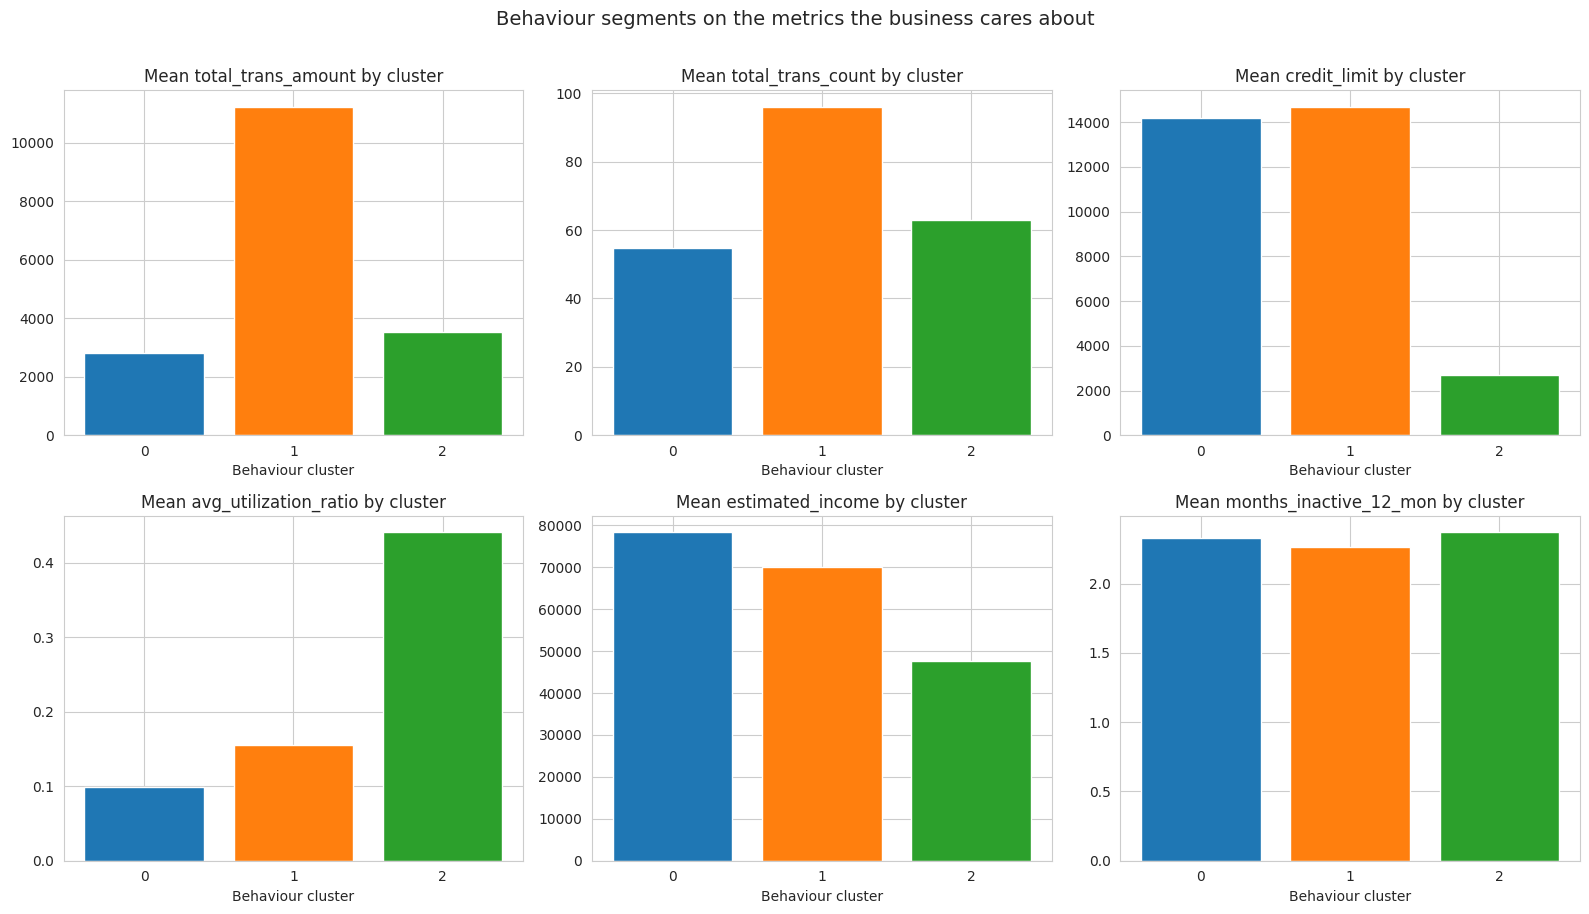

In [119]:
key = ['total_trans_amount', 'total_trans_count', 'credit_limit',
       'avg_utilization_ratio', 'estimated_income', 'months_inactive_12_mon']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), key):
    vals = seg.groupby('bcluster')[col].mean()
    ax.bar([str(i) for i in vals.index], vals.values, color=[pal[i] for i in vals.index])
    ax.set_title('Mean ' + col + ' by cluster')
    ax.set_xlabel('Behaviour cluster')
plt.suptitle('Behaviour segments on the metrics the business cares about', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [120]:
summary = seg.groupby(['bcluster', 'behaviour_segment'])[profile_cols].mean().round(2)
summary.to_csv('segment_profiles.csv')
seg[['customer_id', 'bcluster', 'behaviour_segment', 'cluster']].rename(
    columns={'bcluster': 'segment_id', 'cluster': 'model_a_cluster'}
).to_csv('customer_segments.csv', index=False)
print('Wrote segment_profiles.csv (' + str(len(summary)) + ' rows) and customer_segments.csv (' + str(len(seg)) + ' rows)')
summary.T

Wrote segment_profiles.csv (3 rows) and customer_segments.csv (10127 rows)


bcluster,0,1,2
behaviour_segment,Low utilisation,High basket size,Low credit limit
age,46.64,45.50,46.35
dependent_count,2.41,2.39,2.28
estimated_income,78343.15,70104.28,47631.80
months_on_book,36.35,35.23,35.83
total_relationship_count,4.24,2.22,3.97
months_inactive_12_mon,2.33,2.27,2.37
credit_limit,14172.47,14692.64,2707.94
total_trans_amount,2815.80,11222.66,3522.76
total_trans_count,54.72,96.09,62.94


## 10. Conclusions

### What the segmentation found

Three behavioural segments, selected at `k=3` by silhouette maximum (0.1479):

| | Cluster 0: affluent but idle | Cluster 1: heavy spenders | Cluster 2: thin-limit revolvers |
|---|---|---|---|
| **Customers** | 3,669 (36.2%) | 1,496 (14.8%) | 4,962 (49.0%) |
| **Estimated income** | $78,343 (index 126) | $70,104 (113) | $47,632 (77) |
| **Credit limit** | $14,172 (164) | $14,693 (170) | $2,708 (31) |
| **Annual spend** | $2,816 (64) | $11,223 (255) | $3,523 (80) |
| **Transactions** | 54.7 (84) | 96.1 (148) | 62.9 (97) |
| **Basket size** | $50.79 (81) | $115.64 (185) | $55.37 (88) |
| **Utilisation** | 0.10 (36) | 0.16 (57) | 0.44 (160) |
| **Products held** | 4.24 (111) | 2.22 (58) | 3.97 (104) |

*(index: 100 = portfolio average)*

**Cluster 2 is half the book.** Nearly 5,000 customers on an average limit of $2,708, running 44% utilisation against it. This is where interest revenue comes from and where credit risk concentrates. Their spend of $3,523 is below the $4,404 portfolio average only because the limit caps it, not because they are disengaged: they transact 63 times a year, essentially the portfolio norm. The obvious action is a risk-screened line-increase programme, because the constraint on their spend is the limit rather than the appetite.

**Cluster 1 is 15% of customers and the revenue engine.** Average spend of $11,223 is 2.6 times the portfolio average, on a basket size of $115.64 against $62 overall. The striking number is product holdings: 2.22 against a portfolio average of 3.8, an index of 58. These are the bank's best card customers and its worst cross-sell penetration. They hold the card and little else.

**Cluster 0 is dormant capacity.** The highest incomes and the second-highest limits, and they use 10% of them. 36% of the portfolio sitting on $14,172 of extended credit generating $2,816 of spend. Nothing here is a credit problem; it is an activation and engagement problem, and the 4.24 products they already hold means the relationship exists and simply is not being used on this card.

### What the modelling found

The first model was wrong in a way that would have survived a casual review. It scored a respectable silhouette of 0.1435 at `k=6` and produced six clusters of plausible size. It was also, in four of those six clusters, a one-hot encoding of marital status: mean marital purity across its clusters was 84.2%, and clusters 1, 3, 4 and 5 were each 100% a single status.

The cause is mechanical. After standardisation, a one-hot column puts a fixed, large distance between two customers who differ on it, while a log-scaled continuous feature typically separates them by a fraction of a standard deviation. Euclidean distance cannot be told that one of those differences is less interesting, so K-means spends its partitions on the splits it can make cleanly.

Dropping the low-cardinality dummies from the distance calculation, while keeping them in the dataset for description, improved every measure that matters:

| | Model A (all features) | Model B (behaviour only) |
|---|---|---|
| Best silhouette | 0.1435 at k=6 | **0.1479 at k=3** |
| Variance in 2 PCA components | 30.1% | **38.8%** |
| Mean marital purity per cluster | 84.2% | **46.3%** (portfolio baseline) |
| Features in the distance metric | 23 | 13 |

Model B scores better on a simpler feature space and produces clusters whose marital composition matches the portfolio, which is what it should look like when the model is no longer keying on it.

### Limitations

- **Silhouette near 0.15 is weak, and the notebook does not pretend otherwise.** These are dense regions on a continuum, not discrete customer types. They are useful for targeting and for sizing opportunities. They are not identities, and a customer near a boundary could reasonably belong to either side.
- **K-means assumes roughly spherical, similarly sized clusters.** Gaussian mixture models would allow elliptical shapes and give soft assignments with a membership probability, which suits a continuum better. HDBSCAN would allow a genuinely unclustered remainder instead of forcing every customer into a group. Both are the natural next test.
- **`estimated_income` is estimated**, not reported, so the income-driven separation partly reflects whatever model produced that estimate.
- **The data is a snapshot.** `months_inactive_12_mon` is a count, not a trend, so the segmentation cannot distinguish a customer who is winding down from one who has always been quiet. A time series of spend per customer would change the actionability of cluster 0 considerably.
- **No causal claim is made.** Raising limits for cluster 2 is a hypothesis supported by the utilisation figure, not a finding; it needs a controlled test before it becomes a programme.